## Biological Enrichment of High-Confidence Candidate Genes

To assess whether VIPER’s top-ranked variants point to biologically plausible mechanisms, we analyzed the **Top-35 predicted variants** from the diagnosed IEI cohort (*n* = 205).

We:
1. Extracted the corresponding genes for all Top-35 variants.
2. Selected the **top 80% most frequently occurring genes** (by variant-to-gene mapping) to focus on recurrent signals.
3. Performed **gene set enrichment analysis** using the [GeneCards GeneAnalytics](https://geneanalytics.genecards.org/) platform (web-based), which integrates pathway, disease, and functional annotations from >150 sources.

Here, we visualize the enrichment results for **pathways** and **diseases** as bubble plots, where:
- **X-axis**: Gene ratio (proportion of input genes overlapping the term)
- **Y-axis**: Enriched biological term
- **Bubble size**: Number of overlapping genes
- **Color**: Significance (−log₁₀(adjusted *p*-value))


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load enrichment results (exported from GeneAnalytics)
df_pathway = pd.read_csv("example_Top35_diagnosed_pathway.csv")
df_disease = pd.read_csv("example_Top35_diagnosed_disease.csv")

def plot_enrichment_bubble(data, x='gene_ratio', y='term', size='count', color='-log10(adjp)',
                          title="Gene Enrichment Bubble Chart", figsize=(9, 7), save=False):

    fig, ax = plt.subplots(figsize=figsize)
    fig.patch.set_facecolor('white')
    ax.set_facecolor('white')

    data = data.sort_values(by=color, ascending=False)

    scatter = sns.scatterplot(
        data=data, x=x, y=y, size=size, hue=color,
        sizes=(40, 600), alpha=0.8, palette='viridis', ax=ax, legend='brief'
    )

    ax.grid(axis='x', linestyle='--', color='gray', alpha=0.6)
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_color('black')
        spine.set_linewidth(1.0)
    plt.xlabel('Gene Ratio', fontsize=13)
    plt.ylabel('Enriched Term', fontsize=13)
    plt.title(title, fontsize=15, pad=15)
    handles, labels = scatter.get_legend_handles_labels()
    plt.legend(handles=handles[1:], labels=labels[1:], title=color, loc='lower right', frameon=True)

    plt.tight_layout()
    if save:
        plt.savefig(f"{title.replace(' ', '_')}.pdf", dpi=300, bbox_inches='tight')
        plt.savefig(f"{title.replace(' ', '_')}.png", dpi=300, bbox_inches='tight')
    plt.show()

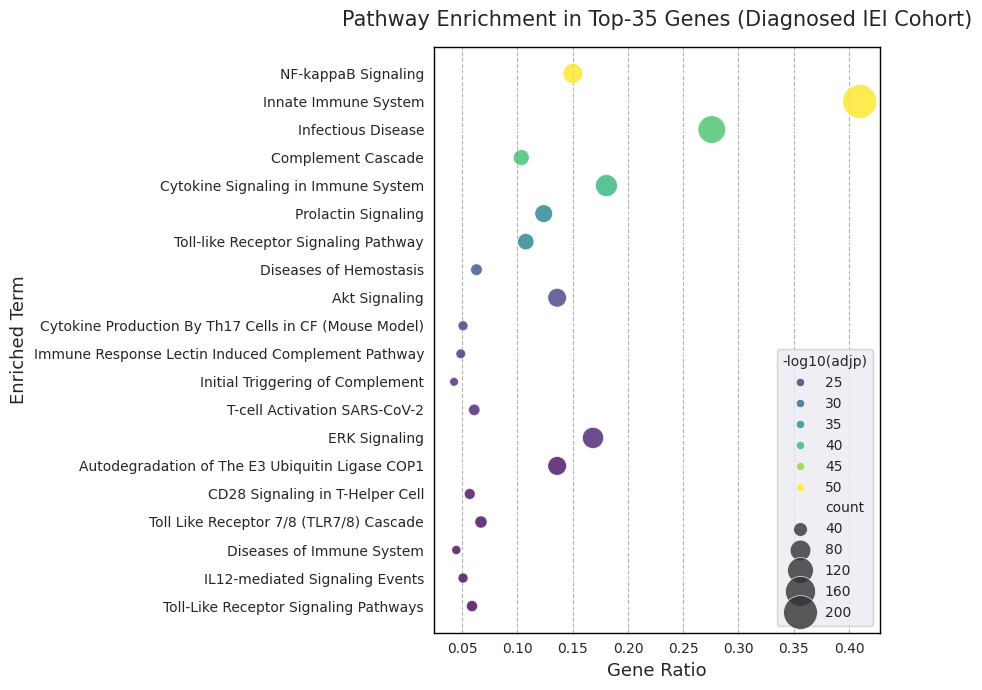

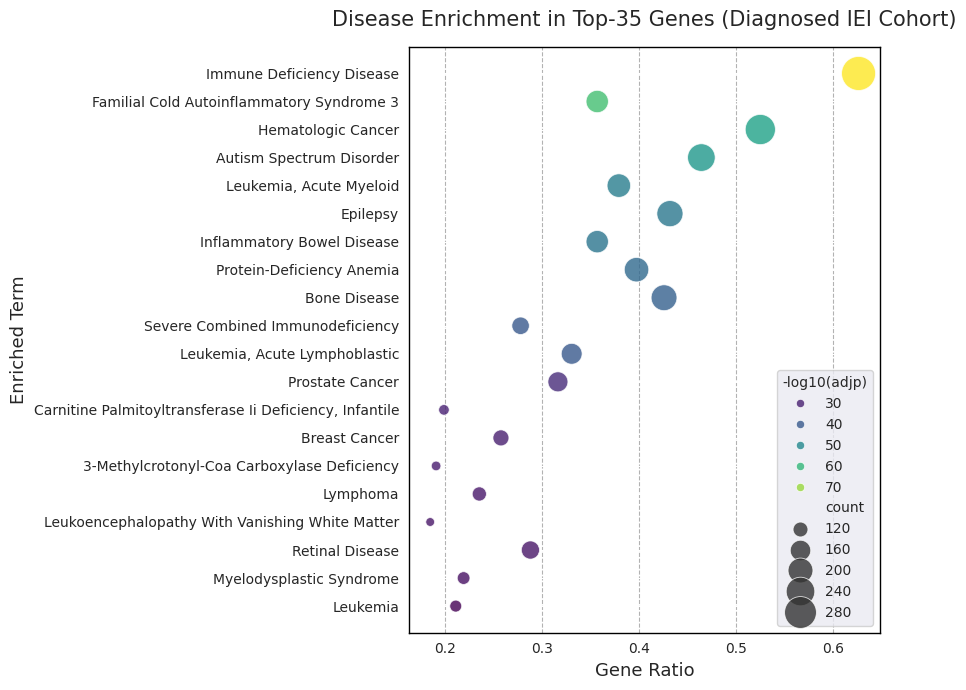

In [3]:
# Plot pathway enrichment
plot_enrichment_bubble(
    df_pathway,
    title="Pathway Enrichment in Top-35 Genes (Diagnosed IEI Cohort)"
)

# Plot disease enrichment
plot_enrichment_bubble(
    df_disease,
    title="Disease Enrichment in Top-35 Genes (Diagnosed IEI Cohort)"
)


## Oligogenic Burden Analysis of High-Confidence Candidate Variants in Undiagnosed IEI Patients

Given that a substantial fraction of patients with suspected Inborn Errors of Immunity (IEI) remain without a molecular diagnosis, we hypothesized that **oligogenic inheritance**—where pathogenic variants in *multiple* immune-related genes jointly contribute to disease—may underlie some unresolved cases.

To test this, we focused on **gene pairs** derived from the top-ranked variants (rank < 35) predicted by VIPER in:
- **Diagnosed cohort**: 205 clinically confirmed + 45 high-confidence model-predicted cases (*n* = 250)
- **Undiagnosed cohort**: 404 patients lacking definitive molecular diagnosis

From the union of 592 candidate genes, we considered all possible gene pairs (*n* = 174,936). For each pair, we constructed a 2×2 contingency table counting how many patients carried **at least one variant in both genes** in each group.

We then performed:
- **Fisher’s exact test** (two-sided) to assess enrichment in undiagnosed vs. diagnosed patients
- **Benjamini–Hochberg (BH) correction** for multiple testing (FDR control)
- Calculation of **odds ratio (OR)** and **relative risk (RR)** with 95% confidence intervals (using Haldane–Anscombe correction to handle zero counts)

This analysis identifies gene pairs significantly overrepresented in undiagnosed individuals, providing candidate oligogenic modules that may explain complex or atypical IEI presentations. Results are summarized in **Supplementary Table S14**.

In [7]:
import numpy as np
import pandas as pd
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests
import os
input_file = "example_gene_pair.csv"
df = pd.read_csv(input_file)

def calculate_rr_or_with_ci(data):
    """
    Compute Fisher's p-value, BH-corrected p-value, RR, OR, and 95% CI for each 2x2 table.

    Input DataFrame must have columns: a, b, c, d
    Returns DataFrame with added columns:
        p_value, p_value_BH, RR, OR, OR_95CI_lower, OR_95CI_upper
    """
    results = {
        'p_value': [],
        'RR': [],
        'OR': [],
        'OR_95CI_lower': [],
        'OR_95CI_upper': []
    }

    for idx, row in data.iterrows():
        a_raw, b_raw, c_raw, d_raw = row['a'], row['b'], row['c'], row['d']

        # Skip invalid entries
        if any(np.isnan([a_raw, b_raw, c_raw, d_raw])) or any(x < 0 for x in [a_raw, b_raw, c_raw, d_raw]):
            for key in results:
                results[key].append(np.nan)
            continue

        # Fisher’s exact test (two-sided)
        try:
            _, p_val = fisher_exact([[a_raw, b_raw], [c_raw, d_raw]], alternative='two-sided')
        except ValueError:
            p_val = np.nan

        # Haldane–Anscombe correction (+0.5) to avoid infinite OR/RR
        a, b, c, d = a_raw + 0.5, b_raw + 0.5, c_raw + 0.5, d_raw + 0.5

        # Relative Risk (RR)
        rr = (a / (a + b)) / (c / (c + d))

        # Odds Ratio (OR) and 95% Wald CI
        or_val = (a * d) / (b * c)
        se = np.sqrt(1/a + 1/b + 1/c + 1/d)
        ln_or = np.log(or_val)
        ci_low = np.exp(ln_or - 1.96 * se)
        ci_up = np.exp(ln_or + 1.96 * se)

        results['p_value'].append(float(p_val) if not np.isnan(p_val) else np.nan)
        results['RR'].append(float(rr))
        results['OR'].append(float(or_val))
        results['OR_95CI_lower'].append(float(ci_low))
        results['OR_95CI_upper'].append(float(ci_up))

    # Append results to DataFrame
    for key, val in results.items():
        data[key] = val

    # Benjamini–Hochberg FDR correction
    pvals = data['p_value'].values.copy()
    valid_mask = (~np.isnan(pvals)) & (pvals >= 0) & (pvals <= 1)

    pvals_bh = np.full(len(pvals), np.nan)
    if valid_mask.sum() > 1:
        _, pvals_bh_valid, _, _ = multipletests(pvals[valid_mask], method='fdr_bh')
        pvals_bh[valid_mask] = pvals_bh_valid
    elif valid_mask.sum() == 1:
        pvals_bh[valid_mask] = pvals[valid_mask]

    data['p_value_BH'] = pvals_bh
    return data

print("Running Fisher’s exact test and effect size estimation...")
df_stats = calculate_rr_or_with_ci(df.copy())
sig_count = df_stats['p_value_BH'].lt(0.05).sum()
print(f"{sig_count:,} gene pairs significant at FDR < 0.05")

# output_file = "example_gene_pair_with_statistics.csv"
# df_stats.to_csv(output_file, index=False)

Running Fisher’s exact test and effect size estimation...
25 gene pairs significant at FDR < 0.05


## Visualization of Enriched Gene Pairs in Undiagnosed IEI Patients

To highlight candidate oligogenic interactions driving unresolved IEI cases, we visualize the **odds ratios (OR)** of significantly enriched gene pairs (FDR < 0.05) identified in the burden analysis.

Each point represents a gene pair, with:
- **X-axis**: log₂(Odds Ratio) — effect size of enrichment in undiagnosed vs. diagnosed patients
- **Horizontal error bars**: 95% confidence interval (log₂ scale)

A vertical dashed line at **log₂(OR) = 0** (i.e., OR = 1) indicates no enrichment.
Pairs to the right are **enriched in undiagnosed patients**, suggesting potential oligogenic contributions.

> **Note**: Protein–protein interaction (PPI) networks for top gene pairs were independently validated using the STRING database (https://string-db.org/), though PPI plotting is not included here due to web-based workflow.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def plot_significant_gene_pairs(input_file="significant_gene_pairs.csv",
                                output_prefix="gene_pair_OR_enrichment",
                                figsize=(9, 7),
                                alpha=0.05,
                                save=False):
    """
    Generate a publication-quality odds ratio plot for significant gene pairs.

    Parameters
    ----------
    input_file : str
        Path to CSV file with columns: 'GroupPair', 'OR', 'CI_lower', 'CI_upper', 'P_BH'
    output_prefix : str
        Prefix for saved figures (PDF/PNG)
    figsize : tuple
        Figure size (width, height) in inches
    alpha : float
        Significance threshold for FDR (default: 0.05)

    Output
    ------
    Saves '{output_prefix}.pdf' and '{output_prefix}.png' at 300 DPI.
    """
    df = pd.read_csv(input_file)

    # Compute log2-transformed metrics
    df['log2_OR'] = np.log2(df['OR'])
    df['log2_CI_lower'] = np.log2(df['CI_lower'])
    df['log2_CI_upper'] = np.log2(df['CI_upper'])

    # Mark significance
    df['significant'] = df['P_BH'] < alpha

    # Sort by effect size (log2_OR) for consistent y-axis ordering
    df = df.sort_values('log2_OR', ascending=True).reset_index(drop=True)
    df['y_pos'] = range(len(df))

    # Create plot
    fig, ax = plt.subplots(figsize=figsize)
    fig.patch.set_facecolor('white')
    ax.set_facecolor('white')

    # Plot each gene pair
    for _, row in df.iterrows():
        x = row['log2_OR']
        y = row['y_pos']
        xerr = [[x - row['log2_CI_lower']], [row['log2_CI_upper'] - x]]
        color = 'tab:red' if row['significant'] else 'lightgray'
        fillstyle = 'full' if row['significant'] else 'none'
        markeredgewidth = 0 if row['significant'] else 1.2

        ax.errorbar(
            x=x, y=y,
            xerr=xerr,
            fmt='o',
            color=color,
            ecolor=color,
            capsize=2,
            markersize=8,
            fillstyle=fillstyle,
            markeredgewidth=markeredgewidth,
            elinewidth=1.0
        )

    # Y-axis: gene pair labels
    ax.set_yticks(df['y_pos'])
    ax.set_yticklabels(df['GroupPair'], fontsize=9)

    # Reference line at OR = 1 (log2 = 0)
    ax.axvline(0, color='black', linestyle='--', linewidth=0.8, alpha=0.6)

    # Labels
    ax.set_xlabel('log₂(Odds Ratio)', fontsize=12)
    ax.set_ylabel('Gene Pair', fontsize=12)

    ax.grid(axis='x', linestyle='-', color='gray', alpha=0.3)
    ax.grid(axis='y', linestyle='-', color='gray', alpha=0.3)
    for spine in ax.spines.values():
        spine.set_color('black')
        spine.set_linewidth(1.0)
    plt.tight_layout()

    # Save high-resolution figures
    png_path = f"{output_prefix}.png"
    pdf_path = f"{output_prefix}.pdf"
    if save:
        plt.savefig(png_path, dpi=300, bbox_inches='tight', facecolor='white')
        plt.savefig(pdf_path, bbox_inches='tight', facecolor='white')
    plt.show()

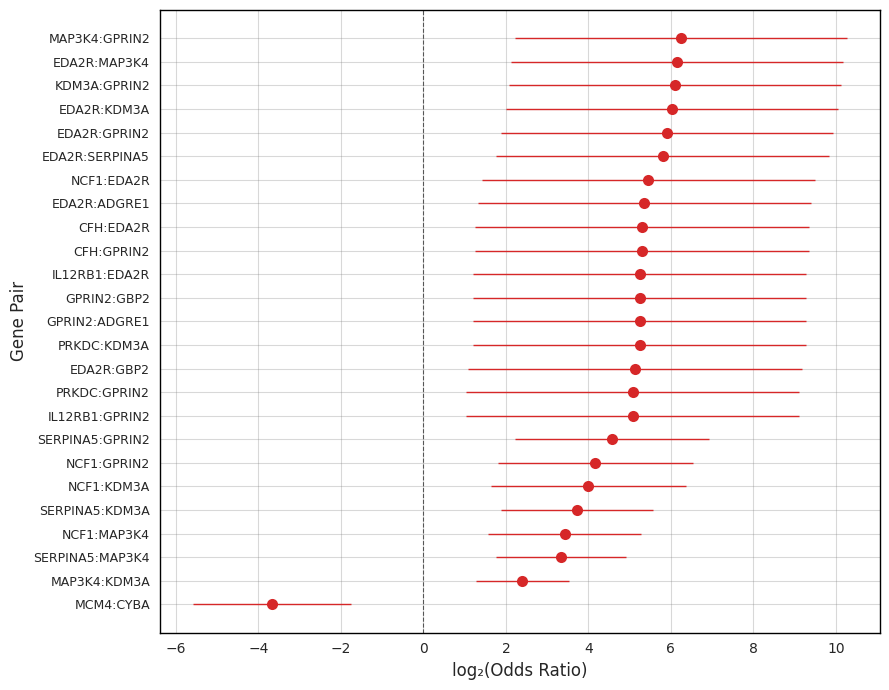

In [5]:
plot_significant_gene_pairs(
    input_file="significant_gene_pairs.csv",
    output_prefix="Fig_SX_GenePair_OR_Enrichment"
)